In [34]:
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pytz
import seaborn as sns

summary_df = pd.read_csv("../data/processed_data/summary.csv")
summary_df['date'] = pd.to_datetime(summary_df['date'], format="mixed", utc=True)
summary_df = summary_df.rename({
    "device_platform": "platform",
    "device_provider": "provider",
    "device_name": "device",
    "win_rate_value": "winrate",
    "win_rate_ci95": "ci95",
    "win_rate_p_value": "p_value",
    "win_rate_var": "var",
    "win_rate_str": "winrate_str",
    "attr_edge_win_rate": "edge_winrate",
    "attr_vertex_win_rate": "vertex_winrate"
}, axis=1)
summary_df.head()

,date,platform,provider,device,strategy,shots,winrate,ci95,p_value,var,winrate_str,attr_job_id,vertex_winrate,edge_winrate,attr_shots,attr_dataID,attr_layout,attr_wiring
0,2023-09-06 18:54:20.039000+00:00,superconducting,ibm,jakarta,4q,1024,0.842729,0.005584,1.0,1.372459e-06,84.2(6),cjsb5jik1qvd8tcm9kt0,0.634696,0.882087,NaN,NaN,NaN,NaN
1,2023-09-06 17:54:20.982000+00:00,superconducting,ibm,guadalupe,4q,1024,0.781827,0.005948,1.0,1.704617e-06,78.1(6),cjsb5jkiifjafcoacbb0,0.507882,0.833654,NaN,NaN,NaN,NaN
2,2023-09-06 17:11:47.908000+00:00,superconducting,ibm,hanoi,4q,1024,0.925415,0.004745,1.0,7.445367e-07,92.5(5),cjsb5jmiel5ovfdojlqg,0.828613,0.943729,NaN,NaN,NaN,NaN
3,2023-09-06 17:11:51.796000+00:00,superconducting,ibm,auckland,4q,1024,0.839822,0.005601,1.0,1.387782e-06,83.9(6),cjsb5k7toe8ecf8p5lr0,0.629116,0.879685,NaN,NaN,NaN,NaN
4,2023-09-07 00:46:45.308000+00:00,superconducting,ibm,quito,4q,1024,0.846746,0.005559,1.0,1.350998e-06,84.6(6),cjsb5kciifjafcoacbv0,0.651576,0.883670,NaN,NaN,NaN,NaN


In [35]:
df = summary_df.copy()
df['year'] = df.date.dt.year
df['date'] = df.date.dt.date
df.sort_values(by=["date"], inplace=True)
df.head()

,date,platform,provider,device,strategy,shots,winrate,ci95,p_value,var,winrate_str,attr_job_id,vertex_winrate,edge_winrate,attr_shots,attr_dataID,attr_layout,attr_wiring,year
0,2023-09-06,superconducting,ibm,jakarta,4q,1024,0.842729,0.005584,1.0,1.372459e-06,84.2(6),cjsb5jik1qvd8tcm9kt0,0.634696,0.882087,NaN,NaN,NaN,NaN,2023
1,2023-09-06,superconducting,ibm,guadalupe,4q,1024,0.781827,0.005948,1.0,1.704617e-06,78.1(6),cjsb5jkiifjafcoacbb0,0.507882,0.833654,NaN,NaN,NaN,NaN,2023
2,2023-09-06,superconducting,ibm,hanoi,4q,1024,0.925415,0.004745,1.0,7.445367e-07,92.5(5),cjsb5jmiel5ovfdojlqg,0.828613,0.943729,NaN,NaN,NaN,NaN,2023
3,2023-09-06,superconducting,ibm,auckland,4q,1024,0.839822,0.005601,1.0,1.387782e-06,83.9(6),cjsb5k7toe8ecf8p5lr0,0.629116,0.879685,NaN,NaN,NaN,NaN,2023
5,2023-09-06,superconducting,ibm,belem,4q,1024,0.873957,0.005334,1.0,1.165837e-06,87.3(6),cjsb5lak1qvd8tcm9mh0,0.715541,0.903927,NaN,NaN,NaN,NaN,2023


In [36]:
def keep_best(df: pd.DataFrame) -> pd.Series:
    idx = df.winrate.argmax()
    return df.iloc[idx]

raw_data = df
df = df.groupby(["provider", "device"]).apply(keep_best).reset_index()
df = df.set_index(["year", "platform", "provider"]).sort_values("date")
df[["date", "strategy", "device", "winrate_str"]]

date   strategy      device winrate_str
year platform        provider                                               
2023 superconducting ibm       2023-09-06         4q        lima     85.8(6)
                     ibm       2023-09-06         4q    auckland     83.9(6)
                     ibm       2023-09-06         4q       belem     87.3(6)
                     ibm       2023-09-06         4q       cairo     84.3(6)
                     ibm       2023-09-06         4q   guadalupe     78.1(6)
                     ibm       2023-09-06         4q       hanoi     92.5(5)
                     ibm       2023-09-06         4q     jakarta     84.2(6)
                     ibm       2023-09-06         4q     nairobi     84.5(6)
                     ibm       2023-09-06         4q      mumbai     85.6(6)
                     ibm       2023-09-07         4q       quito     84.6(6)
                     ibm       2023-09-07         4q      manila     84.2(6)
2024 trapped-ion     umd       2024-07-18  bell_pair      silver     95.2(3)
     superconducting ibm       2024-09-29  bell_pair  sherbrooke     94.3(2)
                     rigetti   2024-09-30  bell_pair     ankaa-2     80.9(4)
                     rigetti   2024-09-30  bell_pair     ankaa-3     91.8(3)
     trapped-ion     duke      2024-10-09  bell_pair        blue     98.2(3)
                     ionq      2024-11-04  bell_pair        aria     95.3(1)
                     duke      2024-11-18  bell_pair        gold    94.5(13)

In [31]:
df.reset_index()

,year,platform,provider,device,date,strategy,shots,winrate,ci95,p_value,var,winrate_str,attr_job_id,vertex_winrate,edge_winrate,attr_shots,attr_dataID,attr_layout,attr_wiring
0,2023,superconducting,ibm,lima,2023-09-06,4q,1024,0.858265,0.005468,1.000000,1.274414e-06,85.8(6),cjsb5mvtoe8ecf8p5ob0,0.679897,0.892011,NaN,NaN,NaN,NaN
1,2023,superconducting,ibm,auckland,2023-09-06,4q,1024,0.839822,0.005601,1.000000,1.387782e-06,83.9(6),cjsb5k7toe8ecf8p5lr0,0.629116,0.879685,NaN,NaN,NaN,NaN
2,2023,superconducting,ibm,belem,2023-09-06,4q,1024,0.873957,0.005334,1.000000,1.165837e-06,87.3(6),cjsb5lak1qvd8tcm9mh0,0.715541,0.903927,NaN,NaN,NaN,NaN
3,2023,superconducting,ibm,cairo,2023-09-06,4q,1024,0.843817,0.005583,1.000000,1.372161e-06,84.3(6),cjsb5lnp8blo0km91iog,0.648926,0.880688,NaN,NaN,NaN,NaN
4,2023,superconducting,ibm,guadalupe,2023-09-06,4q,1024,0.781827,0.005948,1.000000,1.704617e-06,78.1(6),cjsb5jkiifjafcoacbb0,0.507882,0.833654,NaN,NaN,NaN,NaN
5,2023,superconducting,ibm,hanoi,2023-09-06,4q,1024,0.925415,0.004745,1.000000,7.445367e-07,92.5(5),cjsb5jmiel5ovfdojlqg,0.828613,0.943729,NaN,NaN,NaN,NaN
6,2023,superconducting,ibm,jakarta,2023-09-06,4q,1024,0.842729,0.005584,1.000000,1.372459e-06,84.2(6),cjsb5jik1qvd8tcm9kt0,0.634696,0.882087,NaN,NaN,NaN,NaN
7,2023,superconducting,ibm,nairobi,2023-09-06,4q,1024,0.845159,0.005569,1.000000,1.359816e-06,84.5(6),cjsb5nnp8blo0km91kg0,0.651855,0.881730,NaN,NaN,NaN,NaN
8,2023,superconducting,ibm,mumbai,2023-09-06,4q,1024,0.856889,0.005482,1.000000,1.286064e-06,85.6(6),cjsb5mftoe8ecf8p5o10,0.676688,0.890981,NaN,NaN,NaN,NaN
9,2023,superconducting,ibm,quito,2023-09-07,4q,1024,0.846746,0.005559,1.000000,1.350998e-06,84.6(6),cjsb5kciifjafcoacbv0,0.651576,0.883670,NaN,NaN,NaN,NaN


In [37]:
from collections import OrderedDict

brand_colors = OrderedDict({
    "rigetti": "#01B5AD",
    "ibm": "#6F5EFE",
    "ionq": "#EE7C37",
    "duke": "#032169",
    "umd": "#e21833"
})

brand_name_proper = {
    "rigetti": "Rigetti",
    "ibm": "IBM",
    "ionq": "IonQ",
    "duke": "Duke",
    "umd": "UMD/JQI",
}

# Color palette with gray at the end
palette = sns.color_palette(list(brand_colors.values()) + ["#bbbbbb"], len(brand_colors) + 1)

def assign_color_idx(row: pd.Series):
    if row.strategy == "4q":
        return len(brand_colors) + 1
    return list(brand_colors.keys()).index(row.provider)

### Ion trap overall win rate plot

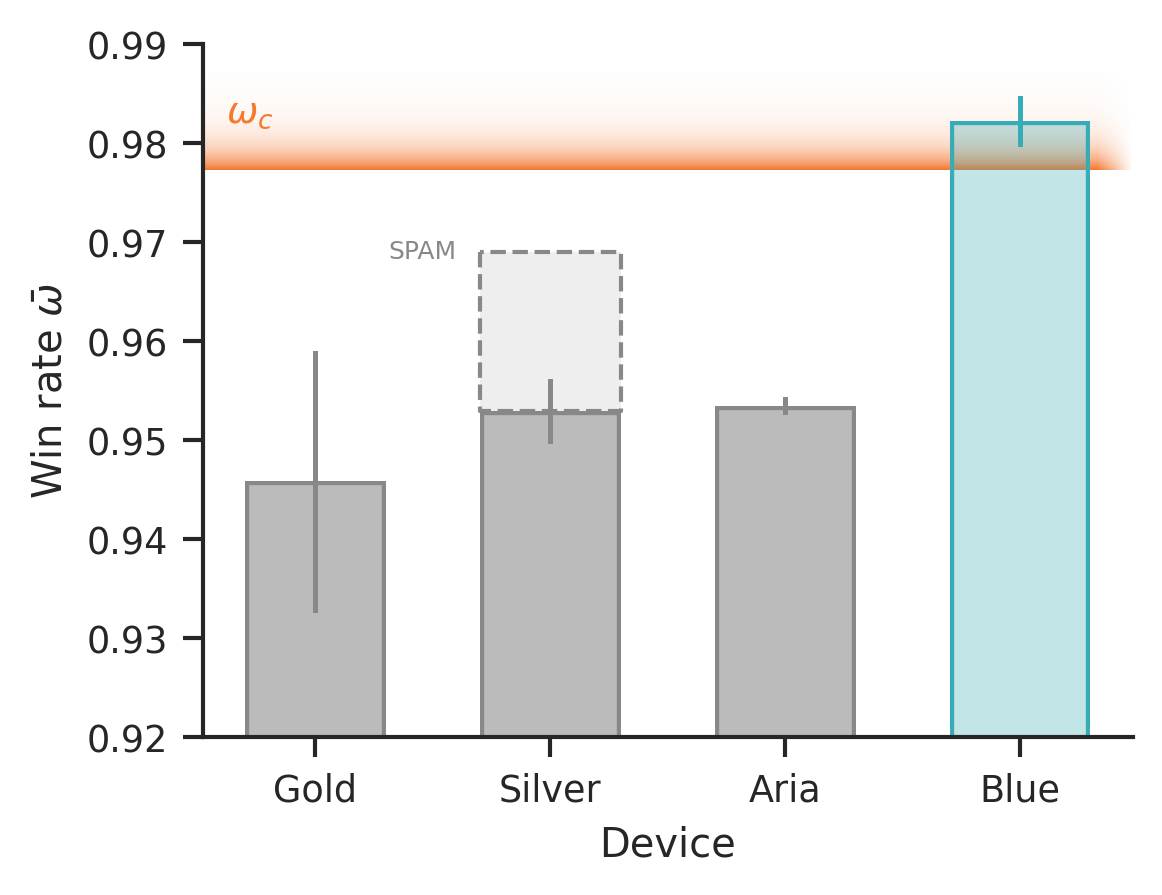

In [39]:
import seaborn.objects as so

plot_df = df.reset_index()
plot_df = (
    plot_df[plot_df["platform"] == "trapped-ion"]
        .sort_values("winrate")
        .reset_index()
)
plot_df["x_idx"] = plot_df.index  # Create numerical x-axis
plot_df["ymin"] = plot_df["winrate"] - plot_df["ci95"]
plot_df["ymax"] = plot_df["winrate"] + plot_df["ci95"]
non_blue_df = plot_df[plot_df["device"] != "blue"]
blue_df = plot_df[plot_df["device"] == "blue"]

# Create the "Explosion" Gradient
# We create a 2D grid: horizontal is the palette, vertical is the fade
res_x, res_y = 500, 500
# palette = sns.color_palette("husl", res_x) # Use 'pastel' or 'husl' for the explosion
full_husl_cmap = sns.husl_palette(as_cmap=True)
palette = [full_husl_cmap(x) for x in np.linspace(0, 0.7, res_x)]
gradient_base = np.array([palette[50] for _ in range(res_y)])[..., :3]

# Create a vertical fade (1 at bottom, 0 at top for alpha)
fade = np.linspace(0, 1, res_y).reshape(-1, 1)
fade = np.exp(-5*fade)
# Combine them (RGBA)
rgba_gradient = np.zeros((res_y, res_x, 4))
rgba_gradient[..., :3] = gradient_base
rgba_gradient[..., 3] = fade # Apply the fade to the alpha channel

# For the last 2% of the gradient on the right, fade it to 0 alpha
dx = int(0.04 * res_x)
fade = np.linspace(1, 0, dx)
rgba_gradient[:, -dx:, 3] *= fade

# Now obtain the color of the gradient at the center of the point where "Blue" device is
pos_data = blue_df.iloc[0]["x_idx"]
pos = pos_data / 3.5
# blue_color = rgba_gradient[0, int(pos * res_x)]
blue_color = palette[400]

p = (
    so.Plot(plot_df, x="x_idx", y="winrate", ymin="ymin", ymax="ymax")
    .add(so.Bar(color="#bbb", edgewidth=1, alpha=1, edgecolor="#888", width=0.6), data=non_blue_df)
    .add(so.Range(color="#888"), data=non_blue_df)
    # .add(so.Bar(color="#48e8d0", edgewidth=1, alpha=1, edgecolor="#16b69e", width=0.6), data=blue_df)
    # .add(so.Range(color="#16b69e"), data=blue_df)
    .add(so.Bar(color=blue_color, edgewidth=1, alpha=0.3, edgecolor=blue_color, width=0.6), data=blue_df)
    .add(so.Range(color=blue_color), data=blue_df)
    .scale(
        # Set discrete labels for the x-axis index
        x=so.Continuous().tick(at=plot_df["x_idx"]).label(like=lambda _, x: plot_df["device"].str.title().iloc[x])
    )
    .label(x="Device", y=r"Win rate $\bar{\omega}$")
    .theme({**sns.axes_style("ticks"), **sns.plotting_context("paper")})
)

fig = plt.figure(figsize=(4, 3), dpi=300)
res = p.on(fig).plot()
ax = fig.axes[0]

# --- Supremacy Region Setup ---
omega_c = 86 / 88
xlim = ax.get_xlim()
ax.set_ylim(bottom=0.92, top=0.99)
ylim = ax.get_ylim()

def sigmoid(x, b=1):
    return (1 + np.exp(-b*x)) ** -1


# Display the gradient only in the "Success Zone"
ax.imshow(rgba_gradient, extent=[*ax.get_xlim(), omega_c, omega_c + 0.01], 
          aspect='auto', zorder=0, origin='lower')

# Omega_c text annotation
pos = 0.05
pos_data = pos * (xlim[1] - xlim[0]) + xlim[0]
color = rgba_gradient[0, int(pos * res_x)]
ax.text(
    pos_data, omega_c + 0.004, 
    r'$\omega_c$', 
    color=color, 
    fontsize=9, 
    va="bottom",
    ha="center"
)

# Silver spam correction
silver_data = non_blue_df[non_blue_df["device"] == "silver"].iloc[0]
spam_corrected_winrate = 0.969
uncorrected_winrate = silver_data["winrate"]
width = 0.6
ax.fill_between(x=[1 - width/2, 1 + width/2], y1=uncorrected_winrate, y2=spam_corrected_winrate, color="#eee", edgecolor="#888", linestyle="--")
ax.text(x=0.7 - 0.1, y=spam_corrected_winrate, s="SPAM", va="center", ha="right", color="#888", size=6)

# Final Polish
ax.set_xlim(xlim)
ax.set_ylim(ylim)
sns.despine(ax=ax)
plt.savefig('ion_trap_results_bar.pdf', bbox_inches="tight")
plt.show()

### Frontier plot (fig. 3)

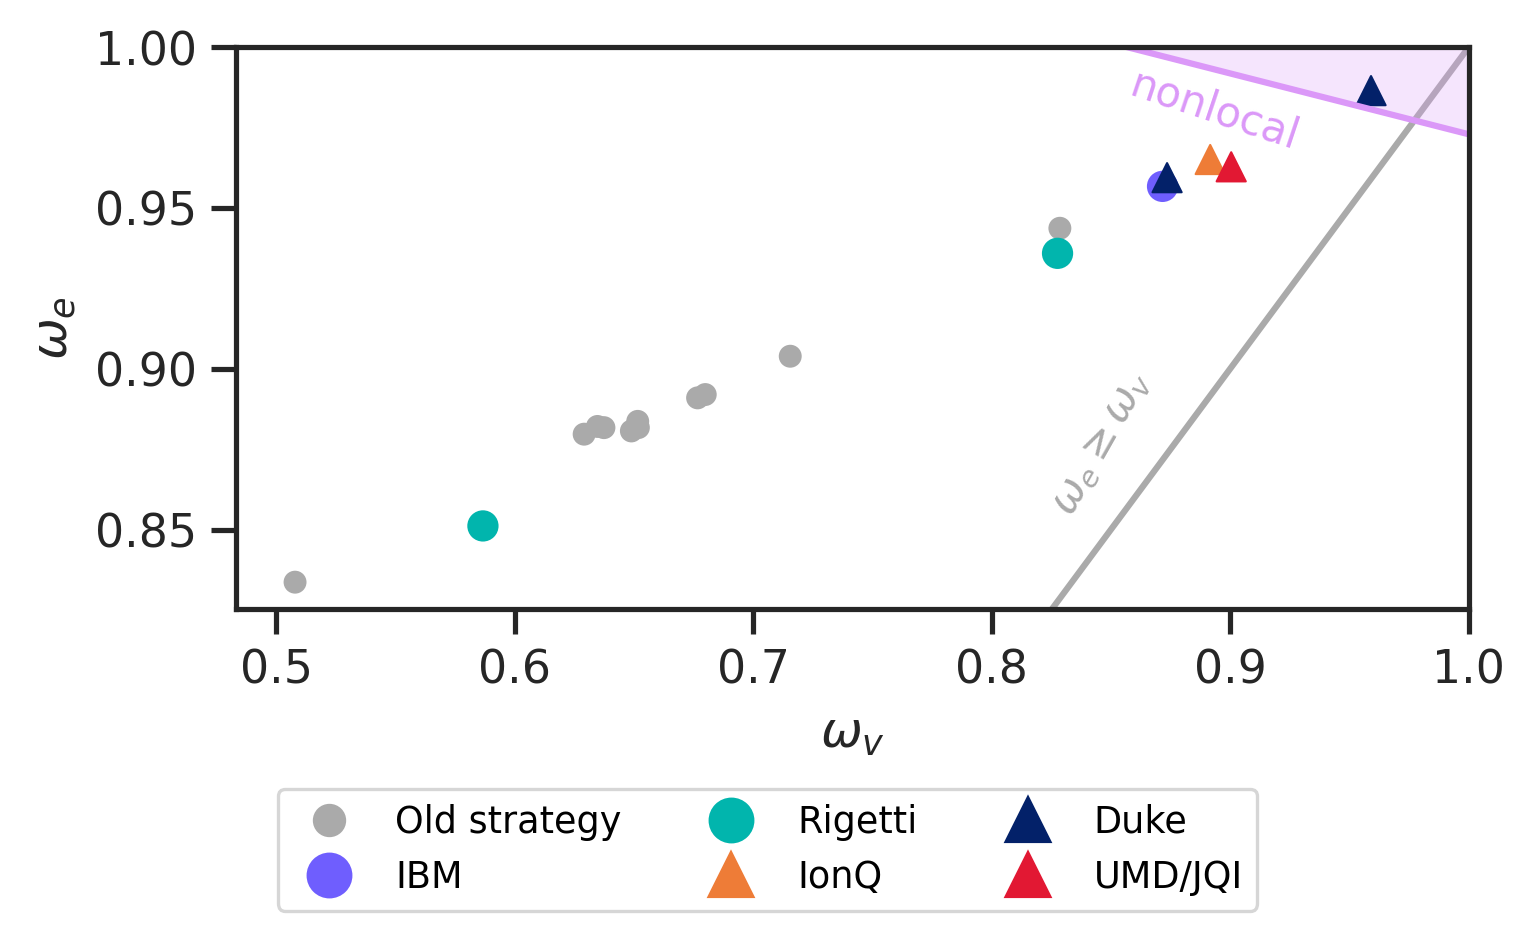

In [43]:
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

data = df.reset_index()
plot_df = (
    data.assign(
        provider_name=data["provider"].map(lambda x: brand_name_proper.get(x.lower(), x.title())),
        is_trapped=data["platform"] == "trapped-ion"
    )
    .sort_values("is_trapped") # Trapped-ion on top
)

# Create the Palette and Logic for Graying
# Update palette keys to match the new 'provider_name' values
palette = {brand_name_proper.get(k.lower(), k.title()): v for k, v in brand_colors.items()}
markers = {"superconducting": "o", "trapped-ion": "^"}

# Logic for the strategy split
old_strategy = plot_df[plot_df["strategy"] == "4q"]
new_strategy = plot_df[plot_df["strategy"] == "bell_pair"]

# 4. Build the Plot
p = (
    so.Plot(
        plot_df,
        x="vertex_winrate", 
        y="edge_winrate", 
        color="provider_name", 
        marker="platform"
    )
    .layout(engine="constrained")
    # Add "old" strategy as gray (no color mapping)
    .add(so.Dot(pointsize=5, stroke=0.5, color="#aaaaaa"), data=old_strategy, legend=False)
    # Add "new" strategy with the brand colors
    .add(so.Dot(pointsize=7, stroke=0.5), data=new_strategy, legend=False)
    .scale(
        color=palette, 
        marker=markers
    )
    .label(
        color="",
        marker="",
        x=r"$\omega_v$",
        y=r"$\omega_e$"
    )
    .theme({**sns.axes_style("ticks")})
)

sns.set_context("paper")
fig = plt.figure(figsize=(5, 3), dpi=300)
res = p.on(fig).plot()
ax = fig.axes[0]

# --- Frontier Line & Fill ---
wv, we, wc = 14 / 88, 74 / 88, 86 / 88
coord1, coord2 = ((wc - we) / wv, 1.0), (1.0, (wc - wv) / we)
fx, fy = np.array([coord1[0], coord2[0]]), np.array([coord1[1], coord2[1]])

nonlocal_region_color = "#DB98F8"
ax.plot(fx, fy, "-", c=nonlocal_region_color, lw=1.5, zorder=1)
ax.fill_between(fx, fy, 1, color=nonlocal_region_color, alpha=0.25, zorder=0)

# --- Asymmetry Line ---
xlim, ylim = ax.get_xlim(), ax.get_ylim()
bot = min(xlim[0], ylim[0])
ax.plot([bot, 1], [bot, 1], "-", c="#aaaaaa", lw=1.5, zorder=-1)

# --- Text Rotations ---
def add_rotated_text(ax, coords, text, color, va, ha, offset_pct=-0.005):
    p1 = ax.transData.transform(coords[0])
    p2 = ax.transData.transform(coords[1])
    angle = np.arctan2(p2[1] - p1[1], p2[0] - p1[0])
    dx, dy = offset_pct * np.array([-np.sin(angle), np.cos(angle)])
    
    ax.text(
        coords[0][0] + dx, coords[0][1] + dy, text,
        fontsize=10, rotation=np.rad2deg(angle),
        color=color, va=va, ha=ha, transform=ax.transData
    )

add_rotated_text(ax, [coord1, coord2], "nonlocal", nonlocal_region_color, "top", "left")
add_rotated_text(ax, [(0.85, 0.85), (1, 1)], r"$\omega_e \geq \omega_v$", "#aaaaaa", "bottom", "center", 0.005)

# Custom legend with markers only (no lines)
legend_elements = [Line2D([0], [0], marker="o", color="#aaaaaa", label="Old strategy", markerfacecolor="#aaaaaa", markersize=7, linestyle="")]
legend_elements += [
    Line2D([0], [0], marker=markers[t], color=palette[b], label=b,
           markerfacecolor=palette[b], markersize=10, linestyle='')
    for b, t in [("IBM", "superconducting"), ("Rigetti", "superconducting"), ("IonQ", "trapped-ion"), ("Duke", "trapped-ion"), ("UMD/JQI", "trapped-ion")]
]
fig.legend(handles=legend_elements, loc="outside lower center", ncols=3)

# Final Touches
ax.set_xlim(xlim[0], 1)
ax.set_ylim(ylim[0], 1)
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
plt.savefig("frontier_plot.pdf", bbox_inches="tight")
plt.show()